In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)

# ============================================================
# LOCATE PROJECT
# ============================================================

def locate_project_root():
    candidates = [Path.cwd(), *Path.cwd().parents]

    for candidate in candidates:
        if (
            (candidate / "Causal Inference" / "model_outputs").exists()
            and (candidate / "Data and Resources" / "final_data.csv").exists()
        ):
            return candidate

    # Fallback if Jupyter was launched from another directory.
    fallback = Path(
        "/Users/albert/Library/CloudStorage/"
        "OneDrive-andrew.cmu.edu/Documents/"
        "CMU 26-27/Undergraduate Research/Victimization/"
        "Code/capstone_victimization"
    )

    if fallback.exists():
        return fallback

    raise FileNotFoundError(
        "Could not locate the capstone_victimization project."
    )


PROJECT_ROOT = locate_project_root()
OUTPUT_DIR = PROJECT_ROOT / "Causal Inference" / "model_outputs"
DATA_DIR = PROJECT_ROOT / "Data and Resources"

SAVE_PLOTS = False
PLOT_DIR = PROJECT_ROOT / "Causal Inference" / "cate_exploratory_plots"

if SAVE_PLOTS:
    PLOT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Save plots: {SAVE_PLOTS}")


# ============================================================
# COVARIATE DEFINITIONS
# ============================================================

numeric_features = [
    "total_number_of_incarcerations",
    "days_r_absent_from_school",
    "r_threatened_to_be_hurt_at_school",
    "r_in_a_fight_at_school",
    "household_net_worth",
    "household_size",
    "asvab_math_verbal_score_percent",
]

# Ordered variables that were previously included in the
# broader categorical list.
ordinal_features = [
    "teachers_good",
    "discipline_is_fair_agree_disagree",
    "percent_of_peers_who_smoke",
    "percent_of_peers_who_get_drunk_1_times_a_month",
    "percent_of_peers_belong_to_a_gang",
    "percent_of_peers_who_have_had_sex",
    "biological_father_education",
    "biological_mother_education",
]

# Nominal and binary variables.
categorical_features = [
    "bullying_victim_before_age_12",
    "r_victim_of_bullying_12_18_years",
    "earliest_arrest_before_18",
    "sex",
    "r_ever_live_through_hard_times",
    "race_ethnicity",
    "mother_serve_prison_sentence",
    "father_serve_prison_sentence",
]

all_features = (
    numeric_features
    + ordinal_features
    + categorical_features
)

ID_COL = "respondent_id"
TREATMENT = "timely_college"
OUTCOME = "violent_victimization_18_24"

PRIMARY_PS_MODEL = "xgb"
PRIMARY_OUTCOME_MODEL = "rf"


# ============================================================
# LOAD DATA AND CROSS-FITTED PREDICTIONS
# ============================================================

data = pd.read_csv(DATA_DIR / "final_data.csv")
ps_predictions = pd.read_csv(
    OUTPUT_DIR / "propensity_oof_predictions.csv"
)
outcome_predictions = pd.read_csv(
    OUTPUT_DIR / "outcome_oof_predictions.csv"
)

# Convert negative NLSY missing codes to NaN.
numeric_columns = (
    data.select_dtypes(include="number")
    .columns
    .difference([ID_COL])
)

data[numeric_columns] = (
    data[numeric_columns]
    .mask(data[numeric_columns] < 0)
)

analysis = ps_predictions.merge(
    outcome_predictions,
    on=[ID_COL, TREATMENT, OUTCOME],
    how="inner",
    validate="one_to_one",
)

analysis = analysis.merge(
    data[[ID_COL, TREATMENT, OUTCOME] + all_features],
    on=ID_COL,
    how="left",
    validate="one_to_one",
    suffixes=("", "_data"),
)

assert analysis[ID_COL].is_unique
assert len(analysis) == len(ps_predictions)
assert len(analysis) == len(outcome_predictions)

assert np.array_equal(
    analysis[TREATMENT].to_numpy(),
    analysis[f"{TREATMENT}_data"].to_numpy(),
)

assert np.array_equal(
    analysis[OUTCOME].to_numpy(),
    analysis[f"{OUTCOME}_data"].to_numpy(),
)

analysis = analysis.drop(
    columns=[
        f"{TREATMENT}_data",
        f"{OUTCOME}_data",
    ]
)


# ============================================================
# RECONSTRUCT PRIMARY AIPW PSEUDO-EFFECT
# ============================================================

z = analysis[TREATMENT].to_numpy(dtype=float)
y = analysis[OUTCOME].to_numpy(dtype=float)

propensity = analysis[
    f"ps_{PRIMARY_PS_MODEL}_mean"
].to_numpy(dtype=float)

mu1 = analysis[
    f"mu1_{PRIMARY_OUTCOME_MODEL}_mean"
].to_numpy(dtype=float)

mu0 = analysis[
    f"mu0_{PRIMARY_OUTCOME_MODEL}_mean"
].to_numpy(dtype=float)

assert np.all((propensity > 0) & (propensity < 1))

pseudo_treated = (
    mu1
    + z * (y - mu1) / propensity
)

pseudo_control = (
    mu0
    + (1 - z) * (y - mu0) / (1 - propensity)
)

analysis["dr_pseudo_effect"] = (
    pseudo_treated - pseudo_control
)

OVERALL_ATE = analysis["dr_pseudo_effect"].mean()

print(f"Analysis sample: {len(analysis):,}")
print(f"Primary propensity model: {PRIMARY_PS_MODEL}")
print(f"Primary outcome model: {PRIMARY_OUTCOME_MODEL}")
print(f"Reconstructed ATE: {OVERALL_ATE:.6f}")
print(
    "Reconstructed ATE in percentage points: "
    f"{100 * OVERALL_ATE:.3f}"
)

display(
    analysis["dr_pseudo_effect"].describe(
        percentiles=[
            0.001,
            0.01,
            0.05,
            0.50,
            0.95,
            0.99,
            0.999,
        ]
    ).to_frame("DR pseudo-effect")
)

Project root: /Users/albert/Library/CloudStorage/OneDrive-andrew.cmu.edu/Documents/CMU 26-27/Undergraduate Research/Victimization/Code/capstone_victimization
Save plots: False
Analysis sample: 8,467
Primary propensity model: xgb
Primary outcome model: rf
Reconstructed ATE: -0.003688
Reconstructed ATE in percentage points: -0.369


,DR pseudo-effect
count,8467.000000
mean,-0.003688
std,0.560795
min,-10.213870
0.1%,-5.339424
1%,-1.764691
5%,-0.367182
50%,0.050182
95%,0.276446
99%,1.740269


In [2]:
def numeric_suitability(dataframe, variable):
    x = pd.to_numeric(
        dataframe[variable],
        errors="coerce",
    )

    observed = x.dropna()
    n = len(dataframe)
    n_observed = len(observed)
    missing_pct = 100 * (1 - n_observed / n)

    if n_observed == 0:
        return {
            "variable": variable,
            "plot_type": "continuous",
            "suitability": "Not available",
            "reason": "No observed values.",
            "n_observed": 0,
            "missing_pct": 100,
            "unique_values": 0,
        }

    n_unique = observed.nunique()
    most_common_share = observed.value_counts(
        normalize=True
    ).iloc[0]

    zero_share = (
        (observed == 0).mean()
        if (observed >= 0).all()
        else np.nan
    )

    skewness = observed.skew()

    concerns = []

    if n_unique < 10:
        concerns.append(
            f"only {n_unique} unique values"
        )

    if most_common_share >= 0.60:
        concerns.append(
            f"{100 * most_common_share:.1f}% share one value"
        )

    if pd.notna(zero_share) and zero_share >= 0.60:
        concerns.append(
            f"{100 * zero_share:.1f}% are zero"
        )

    if pd.notna(skewness) and abs(skewness) >= 3:
        concerns.append(
            f"strong skewness ({skewness:.1f})"
        )

    if missing_pct >= 25:
        concerns.append(
            f"{missing_pct:.1f}% missing"
        )

    severe = (
        n_unique < 5
        or most_common_share >= 0.75
        or (
            pd.notna(zero_share)
            and zero_share >= 0.75
        )
    )

    moderate = (
        n_unique < 20
        or most_common_share >= 0.50
        or (
            pd.notna(skewness)
            and abs(skewness) >= 3
        )
        or missing_pct >= 25
    )

    if severe:
        suitability = "Low"
        recommendation = (
            "Raw scatter is feasible but grouped values "
            "should receive more emphasis."
        )
    elif moderate:
        suitability = "Moderate"
        recommendation = (
            "Scatter is usable with grouped or binned "
            "means and careful interpretation."
        )
    else:
        suitability = "Good"
        recommendation = (
            "Well suited to a scatterplot with a "
            "grouped conditional-mean overlay."
        )

    reason = (
        "; ".join(concerns)
        if concerns
        else "No major plotting concern detected."
    )

    return {
        "variable": variable,
        "plot_type": "continuous",
        "suitability": suitability,
        "reason": reason,
        "recommendation": recommendation,
        "n_observed": n_observed,
        "missing_pct": missing_pct,
        "unique_values": n_unique,
    }


def grouped_suitability(
    dataframe,
    variable,
    plot_type,
):
    x = dataframe[variable]
    observed = x.dropna()

    n = len(dataframe)
    n_observed = len(observed)
    missing_pct = 100 * (1 - n_observed / n)
    counts = observed.value_counts()

    if counts.empty:
        return {
            "variable": variable,
            "plot_type": plot_type,
            "suitability": "Not available",
            "reason": "No observed values.",
            "n_observed": 0,
            "missing_pct": 100,
            "unique_values": 0,
        }

    n_levels = len(counts)
    minimum_n = int(counts.min())

    concerns = []

    if minimum_n < 30:
        concerns.append(
            f"smallest observed level has n={minimum_n}"
        )
    elif minimum_n < 100:
        concerns.append(
            f"smallest observed level has only n={minimum_n}"
        )

    if n_levels > 12:
        concerns.append(
            f"{n_levels} observed levels"
        )

    if missing_pct >= 25:
        concerns.append(
            f"{missing_pct:.1f}% missing"
        )

    if minimum_n < 30 or n_levels > 20:
        suitability = "Low"
        recommendation = (
            "Plot is feasible, but combine sparse levels "
            "before drawing substantive conclusions."
        )
    elif (
        minimum_n < 100
        or n_levels > 10
        or missing_pct >= 25
    ):
        suitability = "Moderate"
        recommendation = (
            "Plot is feasible, but uncertainty and "
            "unequal group sizes are important."
        )
    else:
        suitability = "Good"
        recommendation = (
            "Well suited to a category-specific "
            "mean-and-interval plot."
        )

    reason = (
        "; ".join(concerns)
        if concerns
        else "No major plotting concern detected."
    )

    return {
        "variable": variable,
        "plot_type": plot_type,
        "suitability": suitability,
        "reason": reason,
        "recommendation": recommendation,
        "n_observed": n_observed,
        "missing_pct": missing_pct,
        "unique_values": n_levels,
    }


suitability_rows = []

for variable in numeric_features:
    suitability_rows.append(
        numeric_suitability(
            analysis,
            variable,
        )
    )

for variable in ordinal_features:
    suitability_rows.append(
        grouped_suitability(
            analysis,
            variable,
            plot_type="ordinal",
        )
    )

for variable in categorical_features:
    suitability_rows.append(
        grouped_suitability(
            analysis,
            variable,
            plot_type="categorical",
        )
    )

suitability_report = pd.DataFrame(
    suitability_rows
)

print(
    "PLOT SUITABILITY REPORT\n"
    "The suitability rating concerns visualization, "
    "not whether the variable is causally appropriate.\n"
)

display(
    suitability_report[
        [
            "variable",
            "plot_type",
            "suitability",
            "n_observed",
            "missing_pct",
            "unique_values",
            "reason",
            "recommendation",
        ]
    ].round({"missing_pct": 1})
)

print(
    "\nImportant: the confidence intervals below describe "
    "variation in the current DR pseudo-effects. They do "
    "not repeat the full nuisance-model fitting procedure "
    "and should be treated as exploratory."
)

PLOT SUITABILITY REPORT
The suitability rating concerns visualization, not whether the variable is causally appropriate.



,variable,plot_type,suitability,n_observed,missing_pct,unique_values,reason,recommendation
0,total_number_of_incarcerations,continuous,Low,8434,0.4,11,88.8% share one value; 88.8% are zero; strong ...,Raw scatter is feasible but grouped values sho...
1,days_r_absent_from_school,continuous,Moderate,8185,3.3,59,strong skewness (6.5),Scatter is usable with grouped or binned means...
2,r_threatened_to_be_hurt_at_school,continuous,Low,8362,1.2,30,79.0% share one value; 79.0% are zero; strong ...,Raw scatter is feasible but grouped values sho...
3,r_in_a_fight_at_school,continuous,Low,8366,1.2,22,82.5% share one value; 82.5% are zero; strong ...,Raw scatter is feasible but grouped values sho...
4,household_net_worth,continuous,Moderate,5868,30.7,2237,30.7% missing,Scatter is usable with grouped or binned means...
5,household_size,continuous,Moderate,8467,0.0,16,No major plotting concern detected.,Scatter is usable with grouped or binned means...
6,asvab_math_verbal_score_percent,continuous,Good,6758,20.2,6518,No major plotting concern detected.,Well suited to a scatterplot with a grouped co...
7,teachers_good,ordinal,Good,8453,0.2,4,No major plotting concern detected.,Well suited to a category-specific mean-and-in...
8,discipline_is_fair_agree_disagree,ordinal,Good,8430,0.4,4,No major plotting concern detected.,Well suited to a category-specific mean-and-in...
9,percent_of_peers_who_smoke,ordinal,Good,8361,1.3,5,No major plotting concern detected.,Well suited to a category-specific mean-and-in...



Important: the confidence intervals below describe variation in the current DR pseudo-effects. They do not repeat the full nuisance-model fitting procedure and should be treated as exploratory.


In [3]:
# ============================================================
# DISPLAY LABELS
# ============================================================

binary_label_maps = {
    "bullying_victim_before_age_12": {
        0: "No",
        1: "Yes",
    },
    "r_victim_of_bullying_12_18_years": {
        0: "No",
        1: "Yes",
    },
    "earliest_arrest_before_18": {
        0: "No",
        1: "Yes",
    },
    "sex": {
        1: "Male",
        2: "Female",
    },
    "r_ever_live_through_hard_times": {
        0: "No",
        1: "Yes",
    },
    "mother_serve_prison_sentence": {
        0: "No",
        1: "Yes",
    },
    "father_serve_prison_sentence": {
        0: "No",
        1: "Yes",
    },
}

race_order = [
    "White",
    "Black",
    "Hispanic",
    "Asian",
    "Other",
    "Missing",
]

# Education code 95 is valid but is not part of the
# ordinary numeric ordering.
special_ordinal_values = {
    "biological_father_education": {95},
    "biological_mother_education": {95},
}


def readable_name(variable):
    return variable.replace("_", " ").title()


def safe_filename(variable):
    return re.sub(
        r"[^A-Za-z0-9_-]+",
        "_",
        variable,
    )


def finish_plot(fig, variable, prefix):
    fig.tight_layout()

    if SAVE_PLOTS:
        path = (
            PLOT_DIR
            / f"{prefix}_{safe_filename(variable)}.png"
        )
        fig.savefig(
            path,
            dpi=200,
            bbox_inches="tight",
        )
        print(f"Saved: {path}")

    plt.show()
    plt.close(fig)


# ============================================================
# GROUP SUMMARY
# ============================================================

def summarize_groups(frame, group_column):
    summary = (
        frame
        .dropna(
            subset=[
                group_column,
                "dr_pseudo_effect",
            ]
        )
        .groupby(
            group_column,
            observed=True,
        )["dr_pseudo_effect"]
        .agg(["count", "mean", "std"])
        .reset_index()
        .rename(columns={"count": "n"})
    )

    summary["se"] = (
        summary["std"]
        / np.sqrt(summary["n"])
    )

    summary["ci_lower"] = (
        summary["mean"] - 1.96 * summary["se"]
    )

    summary["ci_upper"] = (
        summary["mean"] + 1.96 * summary["se"]
    )

    # A one-observation category has no estimable SD.
    summary.loc[
        summary["n"] < 2,
        ["se", "ci_lower", "ci_upper"],
    ] = np.nan

    return summary


# ============================================================
# CONTINUOUS PLOTS
# ============================================================

def make_numeric_groups(frame, variable):
    work = frame[
        [variable, "dr_pseudo_effect"]
    ].dropna().copy()

    n_unique = work[variable].nunique()

    # Preserve exact values when the variable has few levels.
    if n_unique <= 12:
        work["_plot_group"] = work[variable]
    else:
        number_of_bins = min(10, n_unique)

        work["_plot_group"] = pd.qcut(
            work[variable],
            q=number_of_bins,
            duplicates="drop",
        )

    grouped = (
        work
        .groupby(
            "_plot_group",
            observed=True,
        )
        .agg(
            x_mean=(variable, "mean"),
            x_min=(variable, "min"),
            x_max=(variable, "max"),
            n=("dr_pseudo_effect", "size"),
            effect_mean=("dr_pseudo_effect", "mean"),
            effect_sd=("dr_pseudo_effect", "std"),
        )
        .reset_index(drop=True)
    )

    grouped["effect_se"] = (
        grouped["effect_sd"]
        / np.sqrt(grouped["n"])
    )

    grouped["ci_lower"] = (
        grouped["effect_mean"]
        - 1.96 * grouped["effect_se"]
    )

    grouped["ci_upper"] = (
        grouped["effect_mean"]
        + 1.96 * grouped["effect_se"]
    )

    return work, grouped


def plot_continuous(frame, variable):
    work, grouped = make_numeric_groups(
        frame,
        variable,
    )

    x = work[variable].to_numpy(dtype=float)
    effect = work[
        "dr_pseudo_effect"
    ].to_numpy(dtype=float)

    # Jitter only when many observations share the same x values.
    if work[variable].nunique() <= 30:
        observed_range = np.nanmax(x) - np.nanmin(x)
        jitter_sd = max(observed_range * 0.004, 0.015)

        rng = np.random.default_rng(2026)
        x_display = (
            x
            + rng.normal(
                0,
                jitter_sd,
                size=len(x),
            )
        )
    else:
        x_display = x

    fig, axes = plt.subplots(
        2,
        1,
        figsize=(9, 9),
        sharex=False,
        gridspec_kw={"height_ratios": [1.2, 1]},
    )

    # Raw scatterplot.
    axes[0].scatter(
        x_display,
        effect,
        s=10,
        alpha=0.10,
        color="tab:blue",
        edgecolors="none",
    )

    axes[0].axhline(
        0,
        color="black",
        linewidth=1,
    )

    axes[0].axhline(
        OVERALL_ATE,
        color="tab:red",
        linestyle="--",
        linewidth=1.3,
        label=f"Overall ATE = {OVERALL_ATE:.4f}",
    )

    axes[0].set_title(
        f"{readable_name(variable)}: raw DR pseudo-effects"
    )

    axes[0].set_xlabel(
        readable_name(variable)
    )

    axes[0].set_ylabel(
        "AIPW pseudo-effect"
    )

    axes[0].legend()
    axes[0].grid(alpha=0.20)

    # Grouped conditional means.
    lower_error = (
        grouped["effect_mean"]
        - grouped["ci_lower"]
    )

    upper_error = (
        grouped["ci_upper"]
        - grouped["effect_mean"]
    )

    axes[1].errorbar(
        grouped["x_mean"],
        grouped["effect_mean"],
        yerr=[
            lower_error,
            upper_error,
        ],
        fmt="o-",
        color="tab:blue",
        ecolor="tab:blue",
        capsize=4,
        linewidth=1.5,
    )

    axes[1].axhline(
        0,
        color="black",
        linewidth=1,
    )

    axes[1].axhline(
        OVERALL_ATE,
        color="tab:red",
        linestyle="--",
        linewidth=1.3,
    )

    axes[1].set_title(
        "Grouped means with exploratory 95% intervals"
    )

    axes[1].set_xlabel(
        readable_name(variable)
    )

    axes[1].set_ylabel(
        "Mean AIPW pseudo-effect"
    )

    axes[1].grid(alpha=0.20)

    finish_plot(
        fig,
        variable,
        prefix="continuous",
    )


# ============================================================
# ORDINAL PLOTS
# ============================================================

def sort_ordinal_values(values, variable):
    values = list(values)
    special = special_ordinal_values.get(
        variable,
        set(),
    )

    regular = [
        value for value in values
        if value not in special
    ]

    special_present = [
        value for value in values
        if value in special
    ]

    try:
        regular = sorted(
            regular,
            key=float,
        )
    except (TypeError, ValueError):
        regular = sorted(
            regular,
            key=str,
        )

    return regular + special_present


def ordinal_label(value, variable):
    if (
        variable
        in special_ordinal_values
        and value
        in special_ordinal_values[variable]
    ):
        return "Ungraded (95)"

    if isinstance(value, float) and value.is_integer():
        return str(int(value))

    return str(value)


def plot_ordinal(frame, variable):
    summary = summarize_groups(
        frame,
        variable,
    )

    order = sort_ordinal_values(
        summary[variable],
        variable,
    )

    summary["_order"] = pd.Categorical(
        summary[variable],
        categories=order,
        ordered=True,
    )

    summary = (
        summary
        .sort_values("_order")
        .reset_index(drop=True)
    )

    positions = np.arange(len(summary))

    lower_error = (
        summary["mean"]
        - summary["ci_lower"]
    )

    upper_error = (
        summary["ci_upper"]
        - summary["mean"]
    )

    fig, ax = plt.subplots(
        figsize=(max(8, 0.65 * len(summary)), 5.5)
    )

    ax.errorbar(
        positions,
        summary["mean"],
        yerr=[
            lower_error,
            upper_error,
        ],
        fmt="o",
        color="tab:blue",
        ecolor="tab:blue",
        capsize=4,
        markersize=6,
        linestyle="none",
    )

    # Connect ordinary ordered levels, but do not connect
    # education code 95 ("Ungraded") to the numeric sequence.
    special = special_ordinal_values.get(
        variable,
        set(),
    )

    regular_mask = ~summary[variable].isin(
        special
    )

    if regular_mask.sum() >= 2:
        ax.plot(
            positions[regular_mask],
            summary.loc[regular_mask, "mean"],
            color="tab:blue",
            alpha=0.65,
            linewidth=1.2,
        )

    ax.axhline(
        0,
        color="black",
        linewidth=1,
    )

    ax.axhline(
        OVERALL_ATE,
        color="tab:red",
        linestyle="--",
        linewidth=1.3,
        label=f"Overall ATE = {OVERALL_ATE:.4f}",
    )

    labels = [
        (
            f"{ordinal_label(row[variable], variable)}"
            f"\n(n={int(row['n']):,})"
        )
        for _, row in summary.iterrows()
    ]

    ax.set_xticks(positions)
    ax.set_xticklabels(
        labels,
        rotation=45,
        ha="right",
    )

    ax.set_xlabel(
        readable_name(variable)
    )

    ax.set_ylabel(
        "Mean AIPW pseudo-effect"
    )

    ax.set_title(
        f"{readable_name(variable)}: ordered-group effects"
    )

    ax.legend()
    ax.grid(axis="y", alpha=0.20)

    missing_n = frame[variable].isna().sum()
    print(
        f"{variable}: ordinal plot excludes "
        f"{missing_n:,} missing observations."
    )

    finish_plot(
        fig,
        variable,
        prefix="ordinal",
    )


# ============================================================
# NOMINAL/BINARY CATEGORICAL PLOTS
# ============================================================

def apply_category_labels(series, variable):
    label_map = binary_label_maps.get(
        variable,
        {},
    )

    def label_value(value):
        if pd.isna(value):
            return "Missing"

        label = label_map.get(
            value,
            value,
        )

        if isinstance(label, float) and label.is_integer():
            return str(int(label))

        return str(label)

    return series.map(label_value)


def plot_categorical(frame, variable):
    work = frame[
        [variable, "dr_pseudo_effect"]
    ].copy()

    work["_category"] = apply_category_labels(
        work[variable],
        variable,
    )

    summary = summarize_groups(
        work,
        "_category",
    )

    if variable == "race_ethnicity":
        available_order = [
            level
            for level in race_order
            if level in set(summary["_category"])
        ]

        summary["_order"] = pd.Categorical(
            summary["_category"],
            categories=available_order,
            ordered=True,
        )

        summary = (
            summary
            .sort_values("_order")
            .reset_index(drop=True)
        )
    else:
        # Put missing last.
        summary["_missing_order"] = (
            summary["_category"] == "Missing"
        )

        summary = (
            summary
            .sort_values(
                ["_missing_order", "_category"]
            )
            .reset_index(drop=True)
        )

    positions = np.arange(len(summary))

    lower_error = (
        summary["mean"]
        - summary["ci_lower"]
    )

    upper_error = (
        summary["ci_upper"]
        - summary["mean"]
    )

    fig_height = max(
        4.5,
        0.65 * len(summary) + 2,
    )

    fig, ax = plt.subplots(
        figsize=(9, fig_height)
    )

    ax.errorbar(
        summary["mean"],
        positions,
        xerr=[
            lower_error,
            upper_error,
        ],
        fmt="o",
        color="tab:blue",
        ecolor="tab:blue",
        capsize=4,
        markersize=7,
        linestyle="none",
    )

    ax.axvline(
        0,
        color="black",
        linewidth=1,
    )

    ax.axvline(
        OVERALL_ATE,
        color="tab:red",
        linestyle="--",
        linewidth=1.3,
        label=f"Overall ATE = {OVERALL_ATE:.4f}",
    )

    labels = [
        f"{row['_category']} (n={int(row['n']):,})"
        for _, row in summary.iterrows()
    ]

    ax.set_yticks(positions)
    ax.set_yticklabels(labels)
    ax.invert_yaxis()

    ax.set_xlabel(
        "Mean AIPW pseudo-effect"
    )

    ax.set_ylabel(
        readable_name(variable)
    )

    ax.set_title(
        f"{readable_name(variable)}: category-specific effects"
    )

    ax.legend()
    ax.grid(axis="x", alpha=0.20)

    finish_plot(
        fig,
        variable,
        prefix="categorical",
    )

Generating exploratory plots for all covariates.
These are univariate descriptive CATE summaries, not final adjusted CATE results.

CONTINUOUS: total_number_of_incarcerations
Suitability: Low
Reason: 88.8% share one value; 88.8% are zero; strong skewness (5.1)
Recommendation: Raw scatter is feasible but grouped values should receive more emphasis.


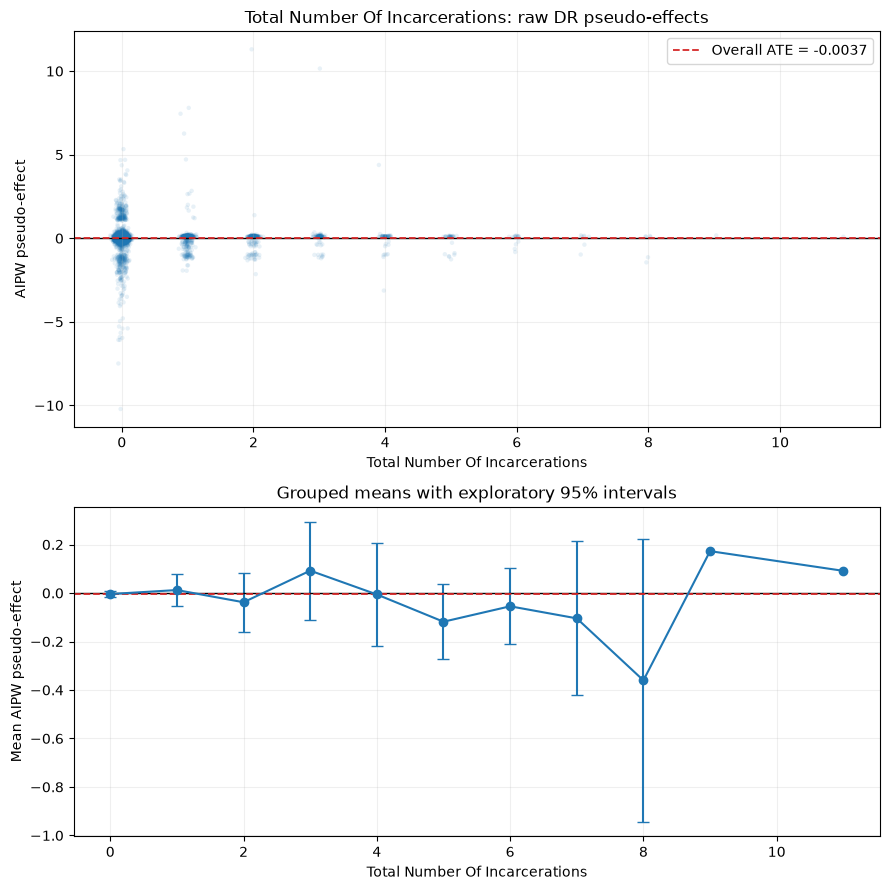

CONTINUOUS: days_r_absent_from_school
Suitability: Moderate
Reason: strong skewness (6.5)
Recommendation: Scatter is usable with grouped or binned means and careful interpretation.


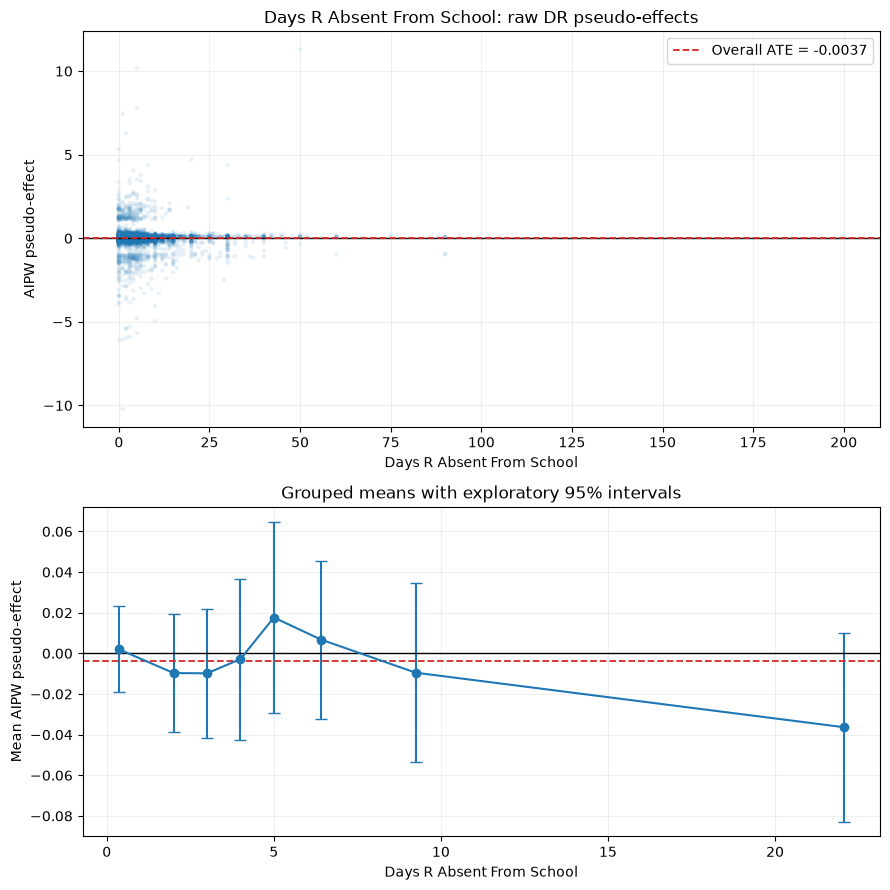

CONTINUOUS: r_threatened_to_be_hurt_at_school
Suitability: Low
Reason: 79.0% share one value; 79.0% are zero; strong skewness (13.5)
Recommendation: Raw scatter is feasible but grouped values should receive more emphasis.


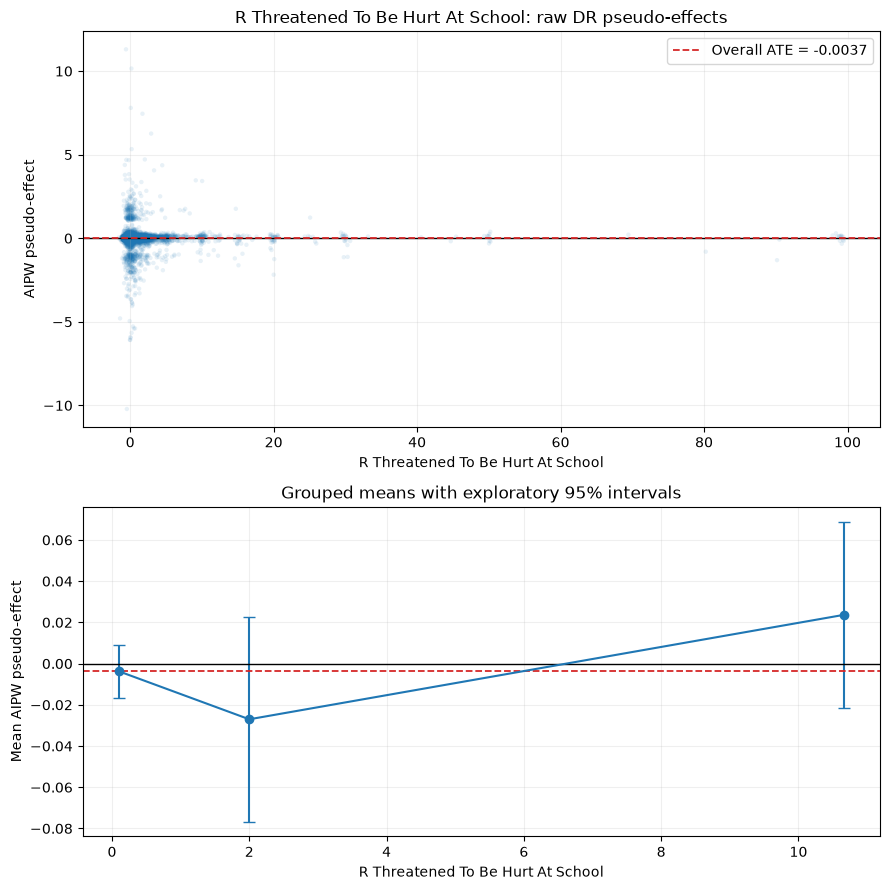

CONTINUOUS: r_in_a_fight_at_school
Suitability: Low
Reason: 82.5% share one value; 82.5% are zero; strong skewness (14.4)
Recommendation: Raw scatter is feasible but grouped values should receive more emphasis.


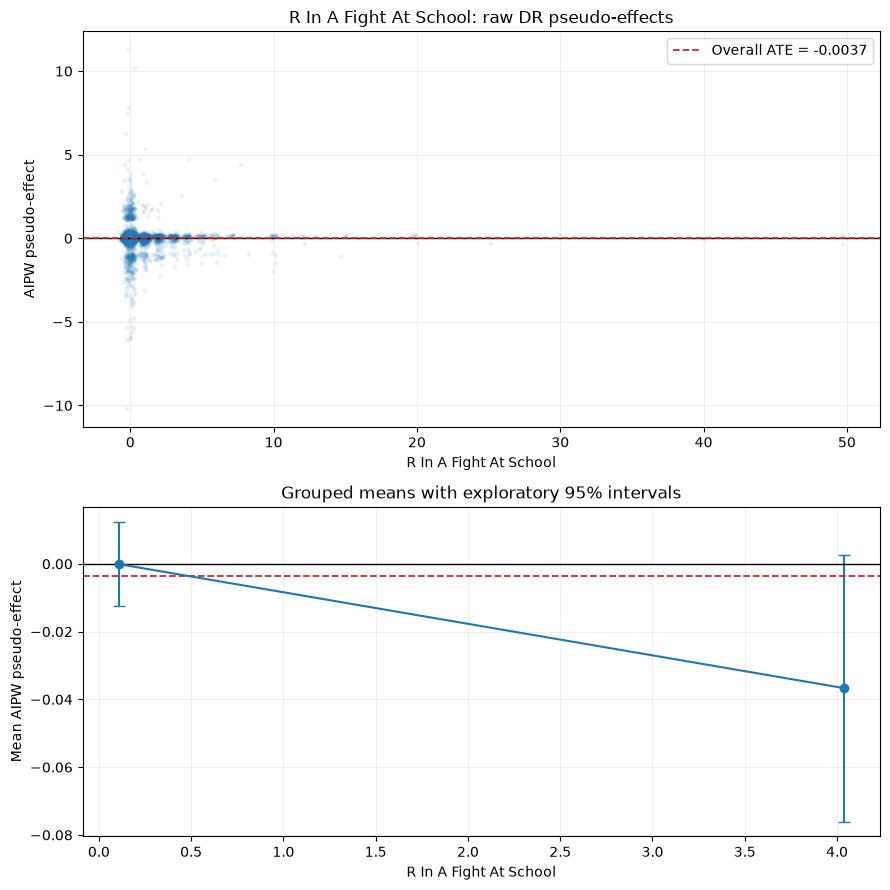

CONTINUOUS: household_net_worth
Suitability: Moderate
Reason: 30.7% missing
Recommendation: Scatter is usable with grouped or binned means and careful interpretation.


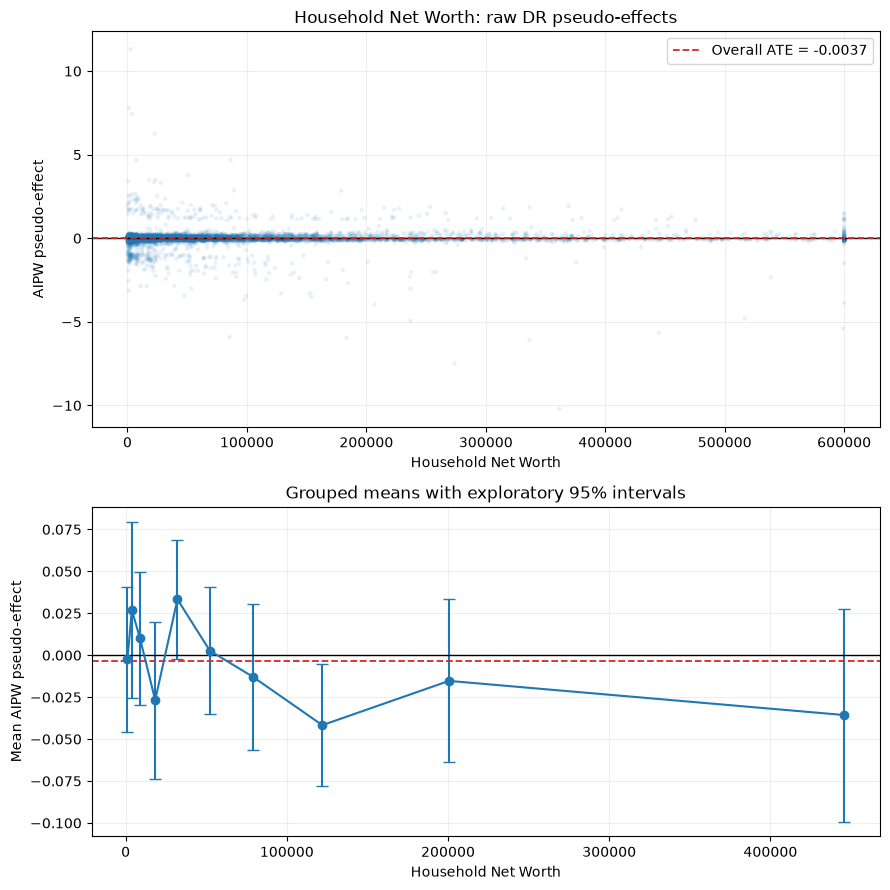

CONTINUOUS: household_size
Suitability: Moderate
Reason: No major plotting concern detected.
Recommendation: Scatter is usable with grouped or binned means and careful interpretation.


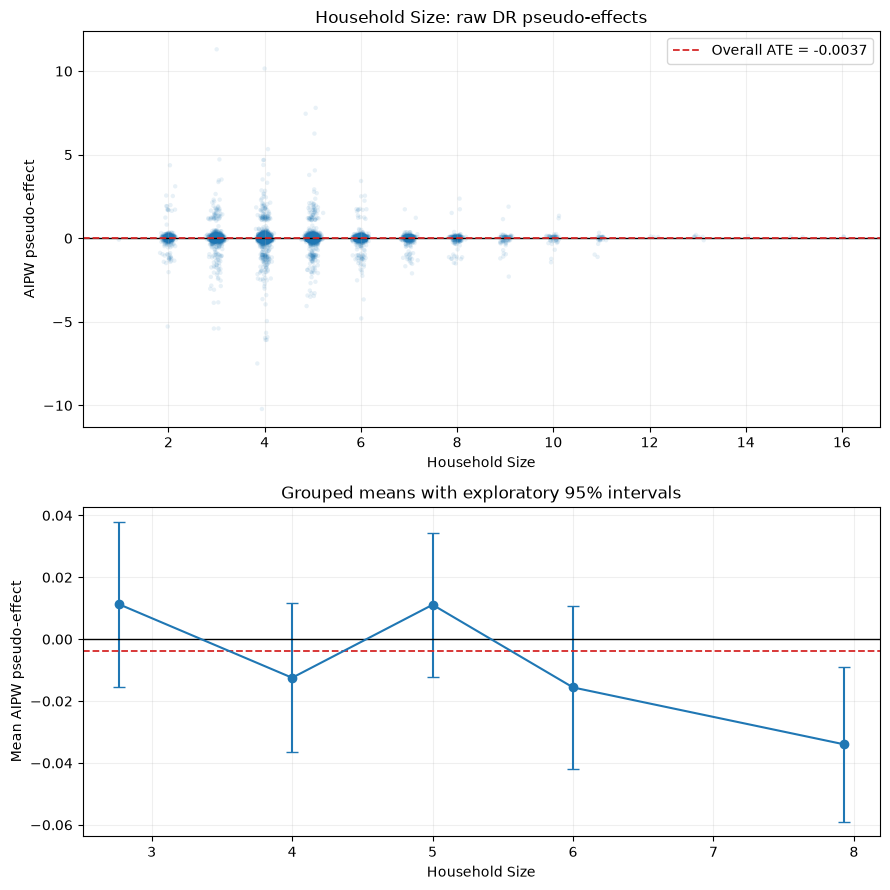

CONTINUOUS: asvab_math_verbal_score_percent
Suitability: Good
Reason: No major plotting concern detected.
Recommendation: Well suited to a scatterplot with a grouped conditional-mean overlay.


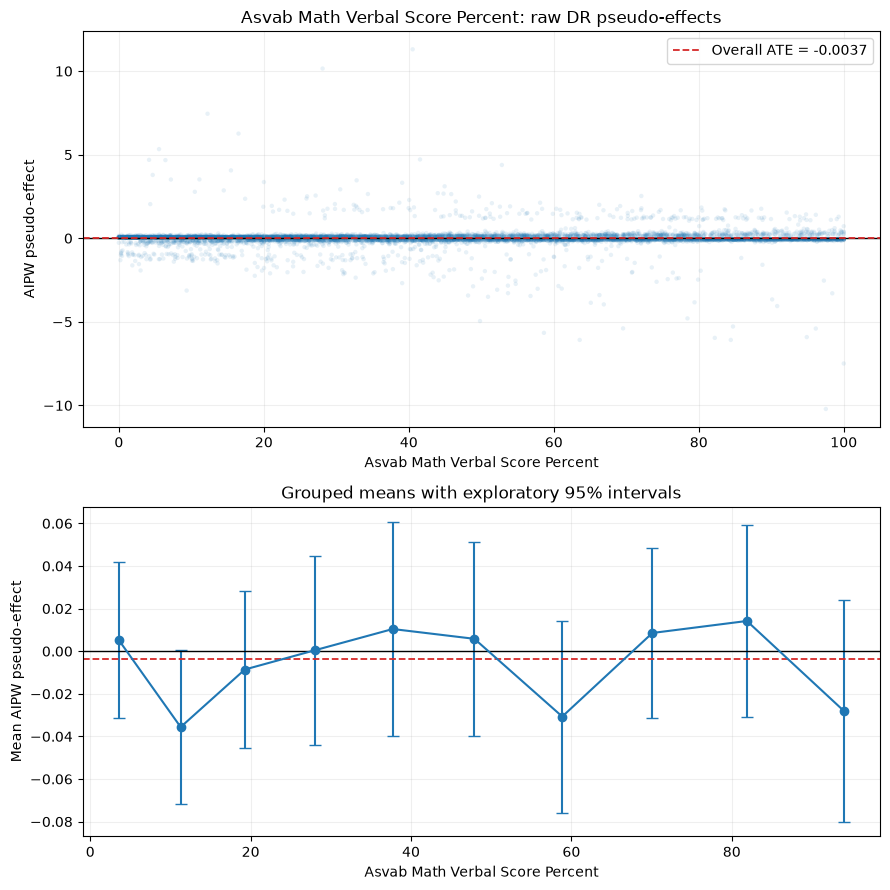

ORDINAL: teachers_good
Suitability: Good
Reason: No major plotting concern detected.
Recommendation: Well suited to a category-specific mean-and-interval plot.
teachers_good: ordinal plot excludes 14 missing observations.


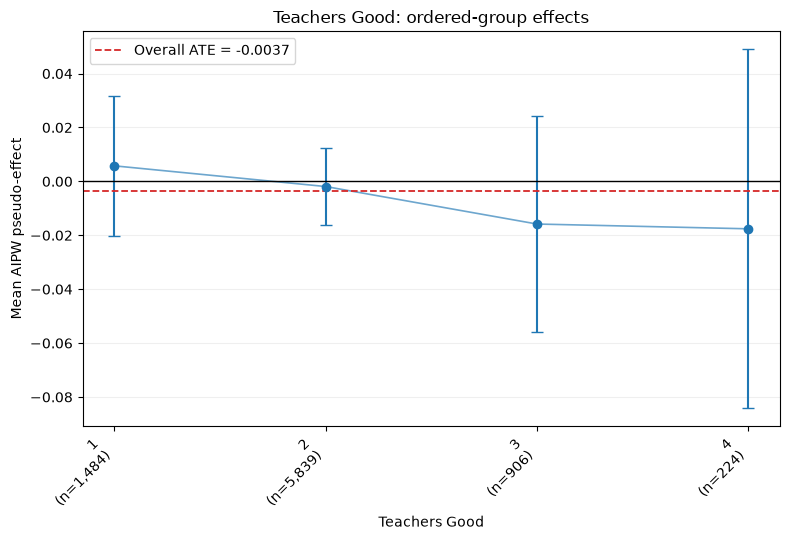

ORDINAL: discipline_is_fair_agree_disagree
Suitability: Good
Reason: No major plotting concern detected.
Recommendation: Well suited to a category-specific mean-and-interval plot.
discipline_is_fair_agree_disagree: ordinal plot excludes 37 missing observations.


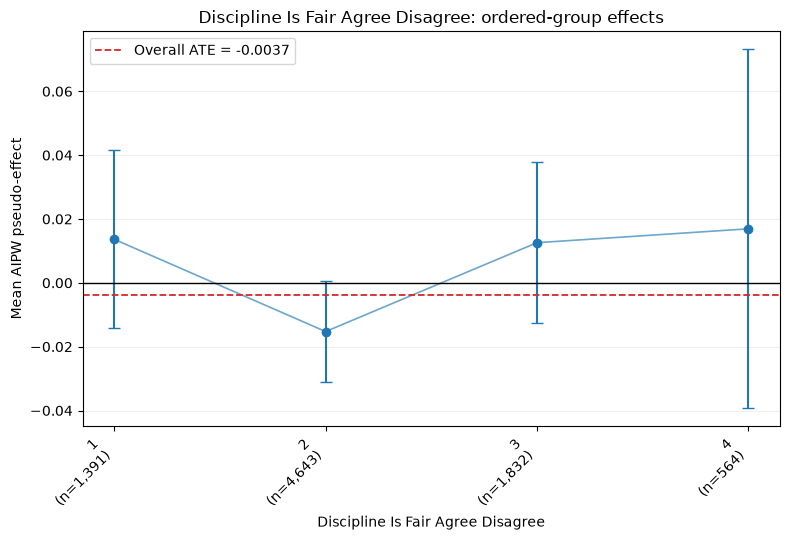

ORDINAL: percent_of_peers_who_smoke
Suitability: Good
Reason: No major plotting concern detected.
Recommendation: Well suited to a category-specific mean-and-interval plot.
percent_of_peers_who_smoke: ordinal plot excludes 106 missing observations.


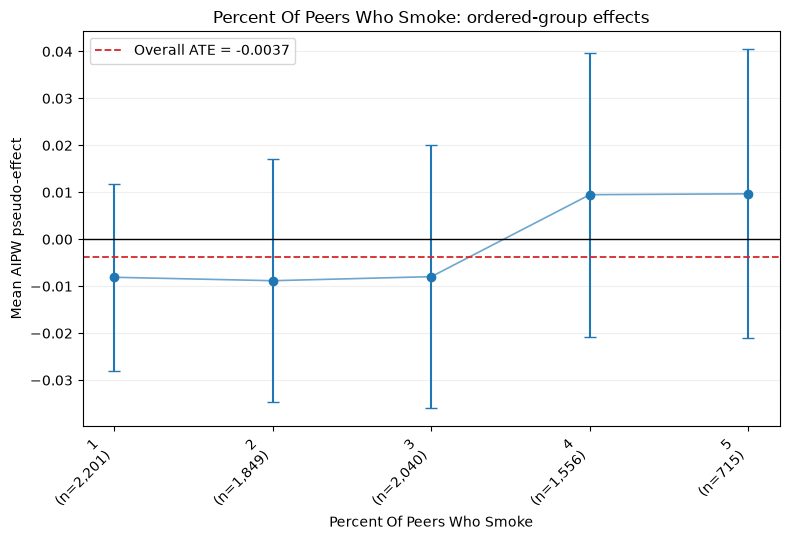

ORDINAL: percent_of_peers_who_get_drunk_1_times_a_month
Suitability: Good
Reason: No major plotting concern detected.
Recommendation: Well suited to a category-specific mean-and-interval plot.
percent_of_peers_who_get_drunk_1_times_a_month: ordinal plot excludes 173 missing observations.


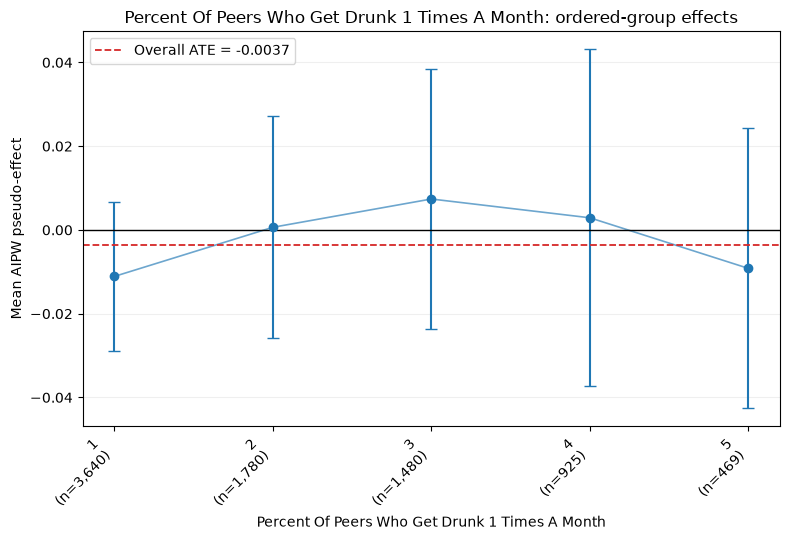

ORDINAL: percent_of_peers_belong_to_a_gang
Suitability: Good
Reason: No major plotting concern detected.
Recommendation: Well suited to a category-specific mean-and-interval plot.
percent_of_peers_belong_to_a_gang: ordinal plot excludes 157 missing observations.


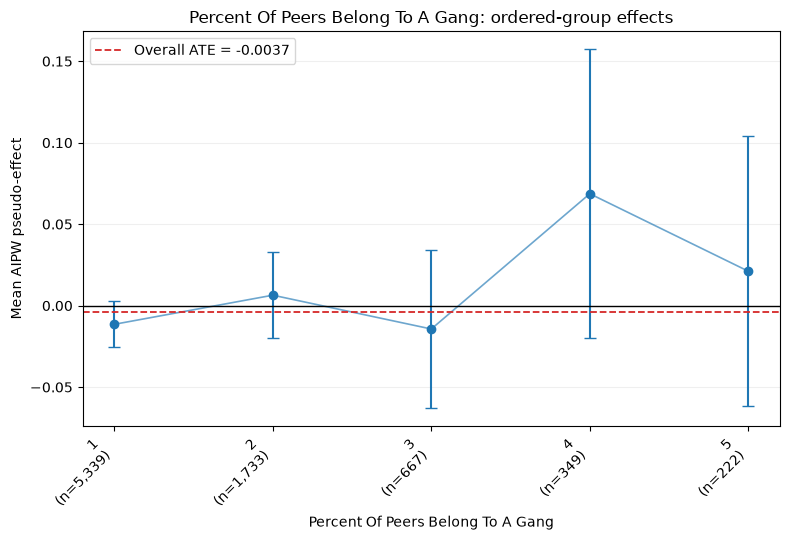

ORDINAL: percent_of_peers_who_have_had_sex
Suitability: Moderate
Reason: 56.3% missing
Recommendation: Plot is feasible, but uncertainty and unequal group sizes are important.
percent_of_peers_who_have_had_sex: ordinal plot excludes 4,767 missing observations.


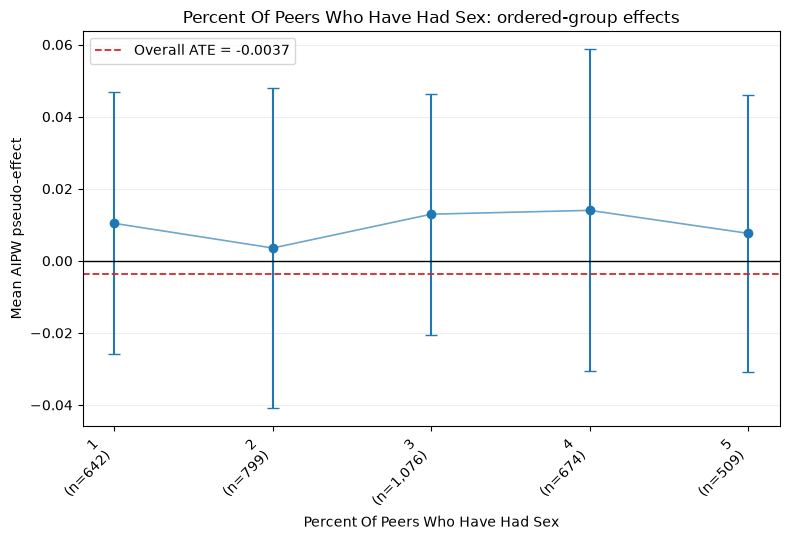

ORDINAL: biological_father_education
Suitability: Low
Reason: smallest observed level has n=1; 21 observed levels
Recommendation: Plot is feasible, but combine sparse levels before drawing substantive conclusions.
biological_father_education: ordinal plot excludes 1,755 missing observations.


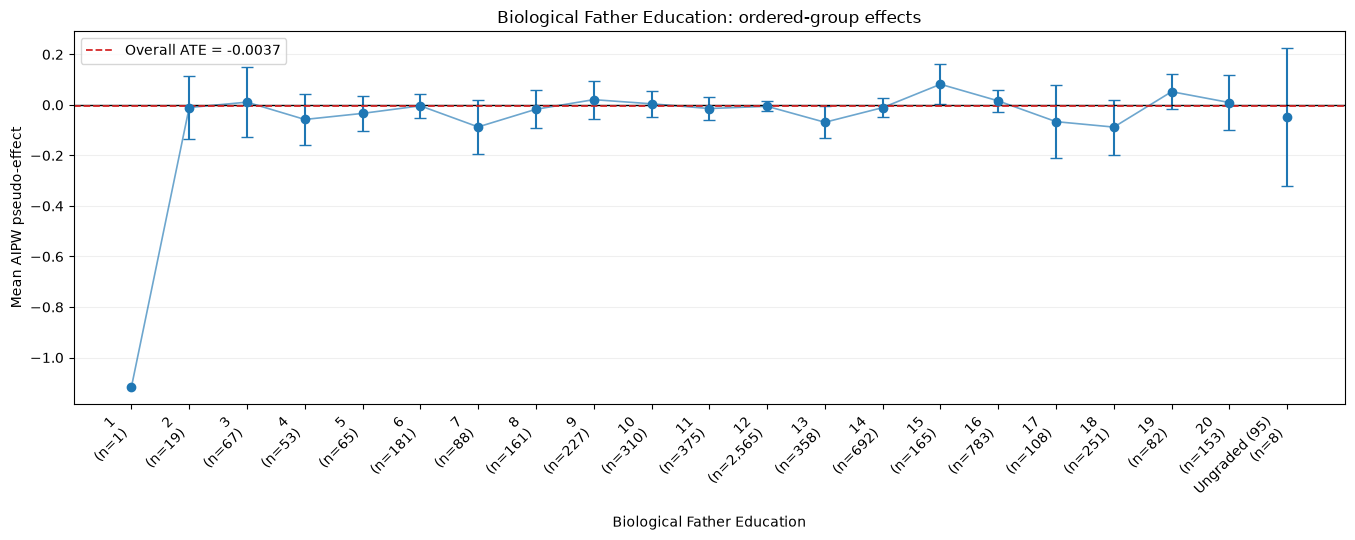

ORDINAL: biological_mother_education
Suitability: Low
Reason: smallest observed level has n=6; 21 observed levels
Recommendation: Plot is feasible, but combine sparse levels before drawing substantive conclusions.
biological_mother_education: ordinal plot excludes 650 missing observations.


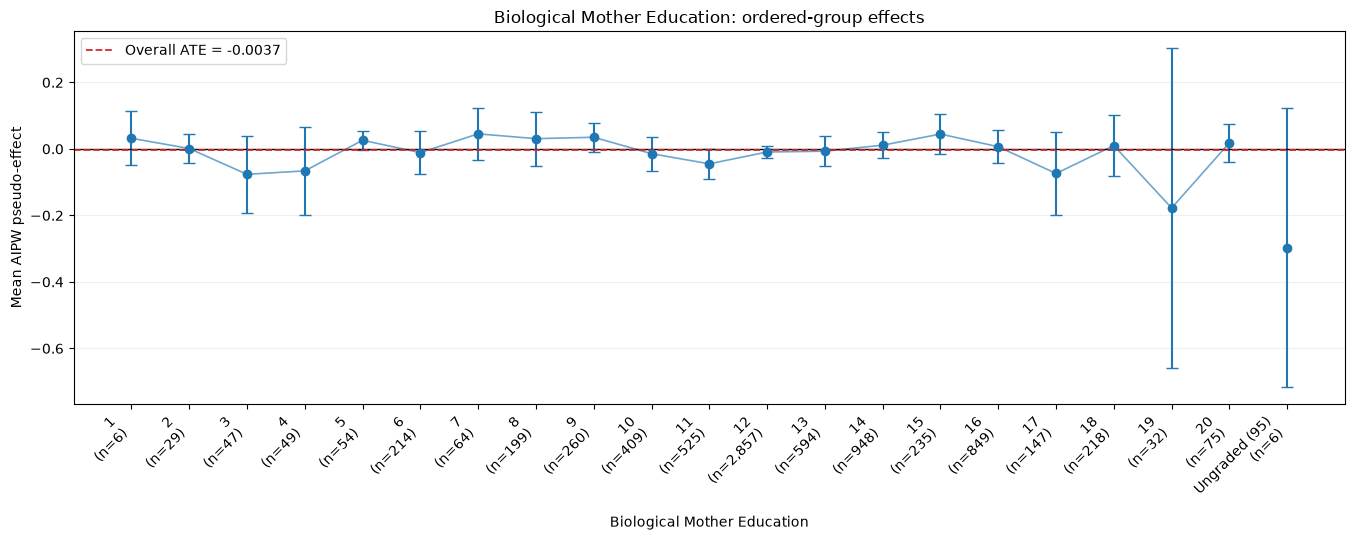

CATEGORICAL: bullying_victim_before_age_12
Suitability: Good
Reason: No major plotting concern detected.
Recommendation: Well suited to a category-specific mean-and-interval plot.


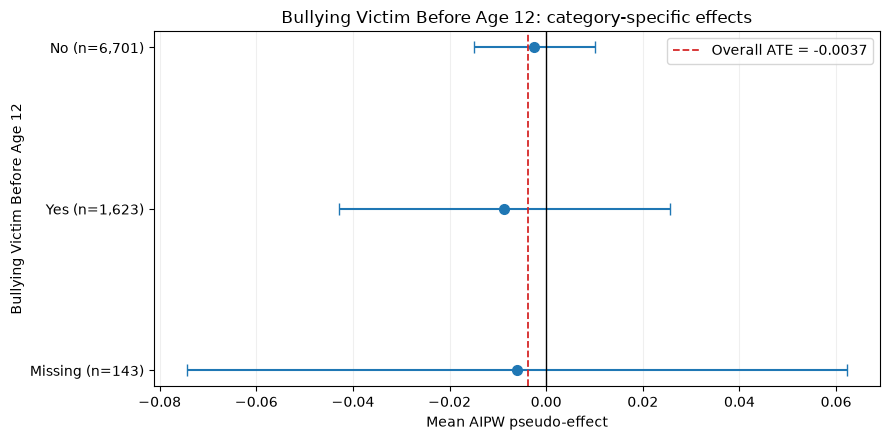

CATEGORICAL: r_victim_of_bullying_12_18_years
Suitability: Good
Reason: No major plotting concern detected.
Recommendation: Well suited to a category-specific mean-and-interval plot.


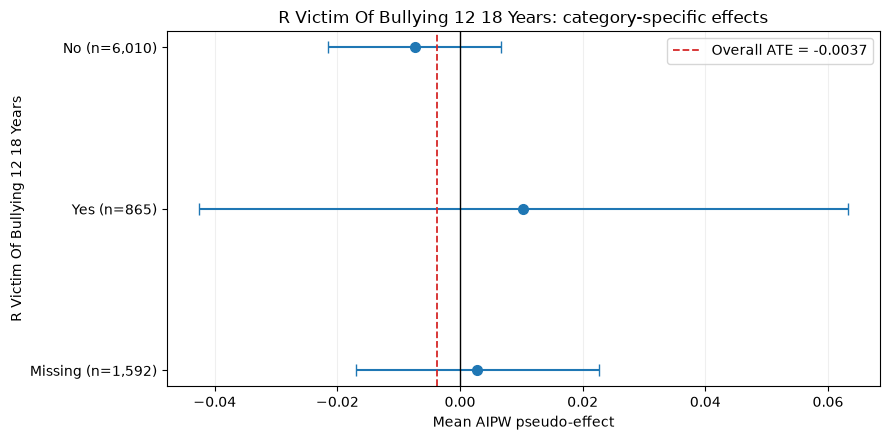

CATEGORICAL: earliest_arrest_before_18
Suitability: Good
Reason: No major plotting concern detected.
Recommendation: Well suited to a category-specific mean-and-interval plot.


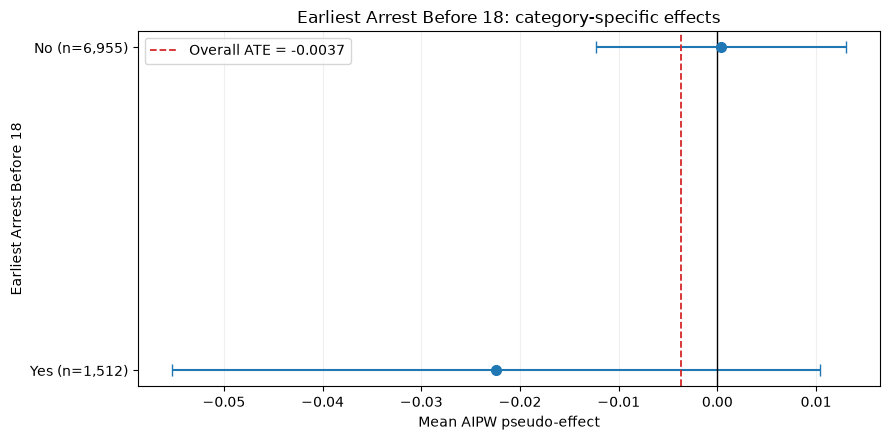

CATEGORICAL: sex
Suitability: Good
Reason: No major plotting concern detected.
Recommendation: Well suited to a category-specific mean-and-interval plot.


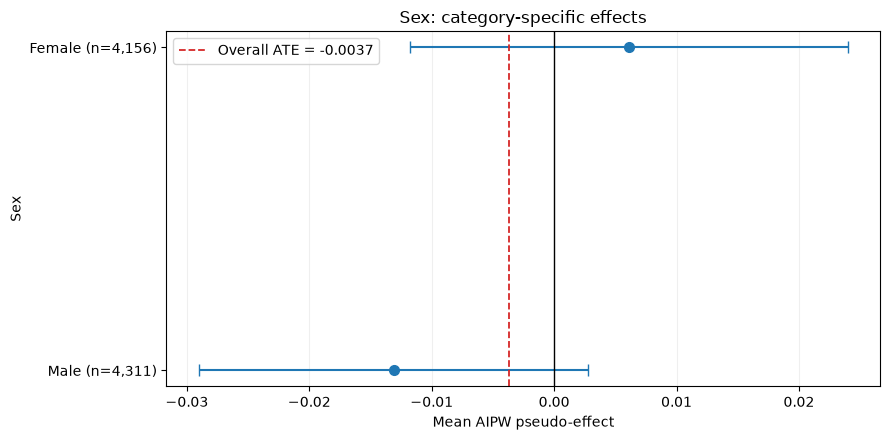

CATEGORICAL: r_ever_live_through_hard_times
Suitability: Good
Reason: No major plotting concern detected.
Recommendation: Well suited to a category-specific mean-and-interval plot.


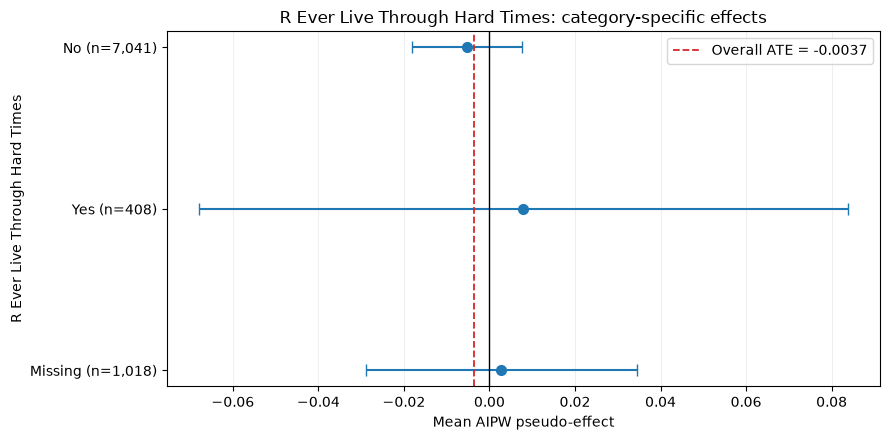

CATEGORICAL: race_ethnicity
Suitability: Good
Reason: No major plotting concern detected.
Recommendation: Well suited to a category-specific mean-and-interval plot.


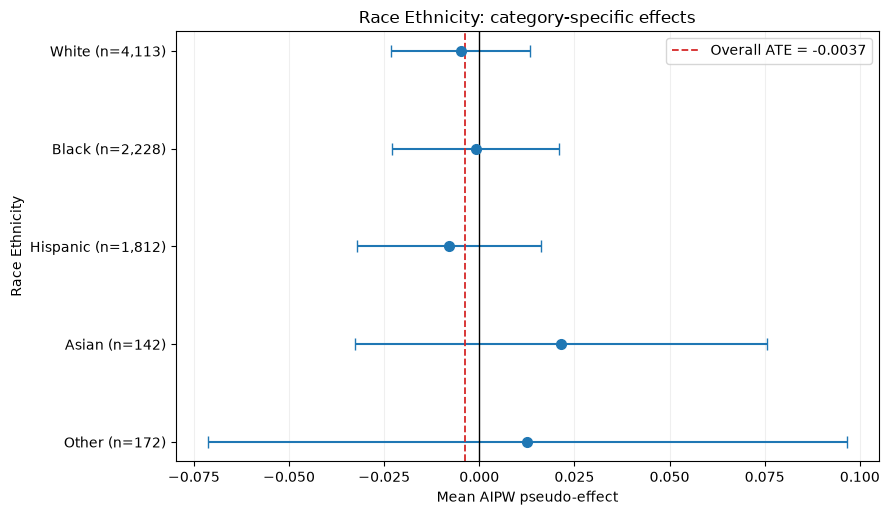

CATEGORICAL: mother_serve_prison_sentence
Suitability: Moderate
Reason: smallest observed level has only n=94
Recommendation: Plot is feasible, but uncertainty and unequal group sizes are important.


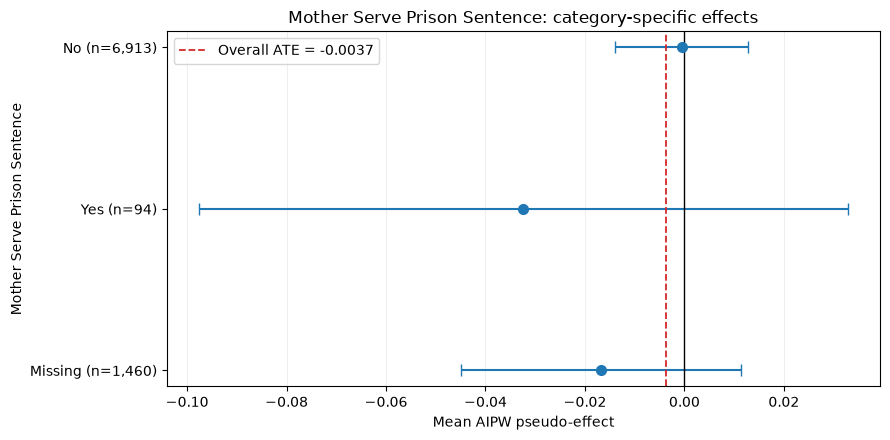

CATEGORICAL: father_serve_prison_sentence
Suitability: Good
Reason: No major plotting concern detected.
Recommendation: Well suited to a category-specific mean-and-interval plot.


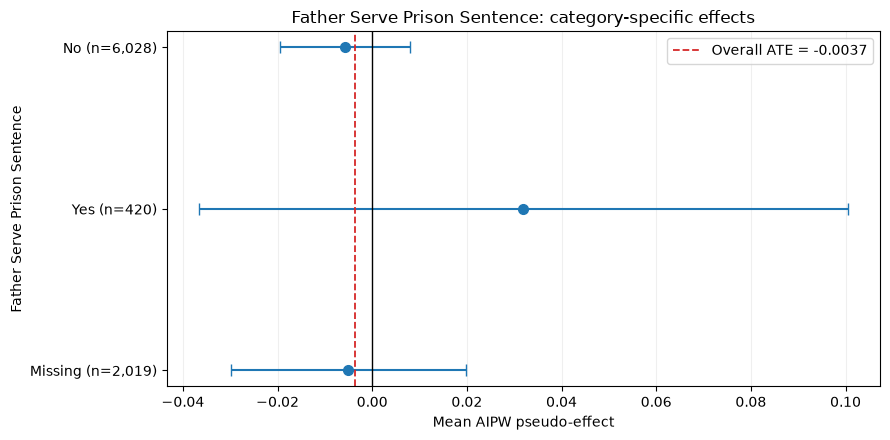

Finished generating all exploratory plots.


In [4]:
print(
    "Generating exploratory plots for all covariates.\n"
    "These are univariate descriptive CATE summaries, "
    "not final adjusted CATE results.\n"
)

for variable in numeric_features:
    report_row = suitability_report.loc[
        suitability_report["variable"] == variable
    ].iloc[0]

    print("=" * 80)
    print(f"CONTINUOUS: {variable}")
    print(f"Suitability: {report_row['suitability']}")
    print(f"Reason: {report_row['reason']}")
    print(
        f"Recommendation: "
        f"{report_row['recommendation']}"
    )

    plot_continuous(
        analysis,
        variable,
    )


for variable in ordinal_features:
    report_row = suitability_report.loc[
        suitability_report["variable"] == variable
    ].iloc[0]

    print("=" * 80)
    print(f"ORDINAL: {variable}")
    print(f"Suitability: {report_row['suitability']}")
    print(f"Reason: {report_row['reason']}")
    print(
        f"Recommendation: "
        f"{report_row['recommendation']}"
    )

    plot_ordinal(
        analysis,
        variable,
    )


for variable in categorical_features:
    report_row = suitability_report.loc[
        suitability_report["variable"] == variable
    ].iloc[0]

    print("=" * 80)
    print(f"CATEGORICAL: {variable}")
    print(f"Suitability: {report_row['suitability']}")
    print(f"Reason: {report_row['reason']}")
    print(
        f"Recommendation: "
        f"{report_row['recommendation']}"
    )

    plot_categorical(
        analysis,
        variable,
    )

print("=" * 80)
print("Finished generating all exploratory plots.")